# Rail Profiles

The other notebooks focus on the wheels. Here I look at the seven rail profiles the trucks were simulated on. Hunting rates change a lot from one rail profile to the next, so I want to see what is different about the rail shapes before we compare wheels across them.

The rail files are in `data/Profiles/Rail profiles`. Each profile has a `.FIT` file and one or more `.BAN` files. The `.BAN` files are MiniProf exports with X, Y, angle, and curvature columns in mm, so I use those.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_folder = Path.cwd()
if project_folder.name == "notebooks":
    project_folder = project_folder.parent

data_folder = project_folder / "data"
rail_folder = data_folder / "Profiles" / "Rail profiles"

for path in sorted(rail_folder.iterdir()):
    print(path.name)

RProfile 1.FIT
RProfile 1L.BAN
RProfile 1R.BAN
RProfile 2.FIT
RProfile 2L.BAN
RProfile 2R.BAN
RProfile 3.FIT
RProfile 3L.BAN
RProfile 3R.BAN
RProfile 4.FIT
RProfile 4L.BAN
RProfile 4R.BAN
RProfile 5.BAN
RProfile 5.FIT
RProfile 6.BAN
RProfile 6.FIT
RProfile 7.BAN
RProfile 7.FIT


## Read the BAN files

Each `.BAN` file starts with `Name=value` header lines, then a blank line, then the profile points. The `ColumnDef` line in the header gives the column names.

In [2]:
def read_ban(path):
    header = {}
    points = []
    in_points = False
    for line in path.read_text().splitlines():
        line = line.strip()
        if not in_points:
            if "=" in line:
                key, value = line.split("=", 1)
                header[key] = value
            elif line == "" and header:
                in_points = True
        elif line:
            points.append([float(value) for value in line.split()])
    columns = header["ColumnDef"].split(",")
    return pd.DataFrame(points, columns=columns)


rails = {}
for path in sorted(rail_folder.glob("*.BAN")):
    name = path.stem.replace("RProfile ", "")
    rails[name] = read_ban(path)

overview = pd.DataFrame({
    name: {
        "points": len(points),
        "x_min": points["X"].min(),
        "x_max": points["X"].max(),
        "y_min": points["Y"].min(),
    }
    for name, points in rails.items()
}).T
display(overview.round(2))

,points,x_min,x_max,y_min
1L,335.0,-32.70,38.01,-21.50
1R,294.0,-34.76,34.76,-12.55
2L,303.0,-35.43,35.43,-12.37
2R,306.0,-35.50,35.50,-12.59
3L,316.0,-35.71,35.71,-17.47
3R,324.0,-33.90,33.90,-24.49
4L,315.0,-35.62,35.62,-17.39
4R,399.0,-37.10,37.10,-24.96
5,323.0,-36.65,37.77,-16.19
6,330.0,-35.96,37.42,-19.06


Rail profiles 1-4 have separate left (`L`) and right (`R`) files. Profiles 5-7 only have one file, so I assume the same shape was used for both rails. That is something to confirm with MxV.

## Plot the rail shapes

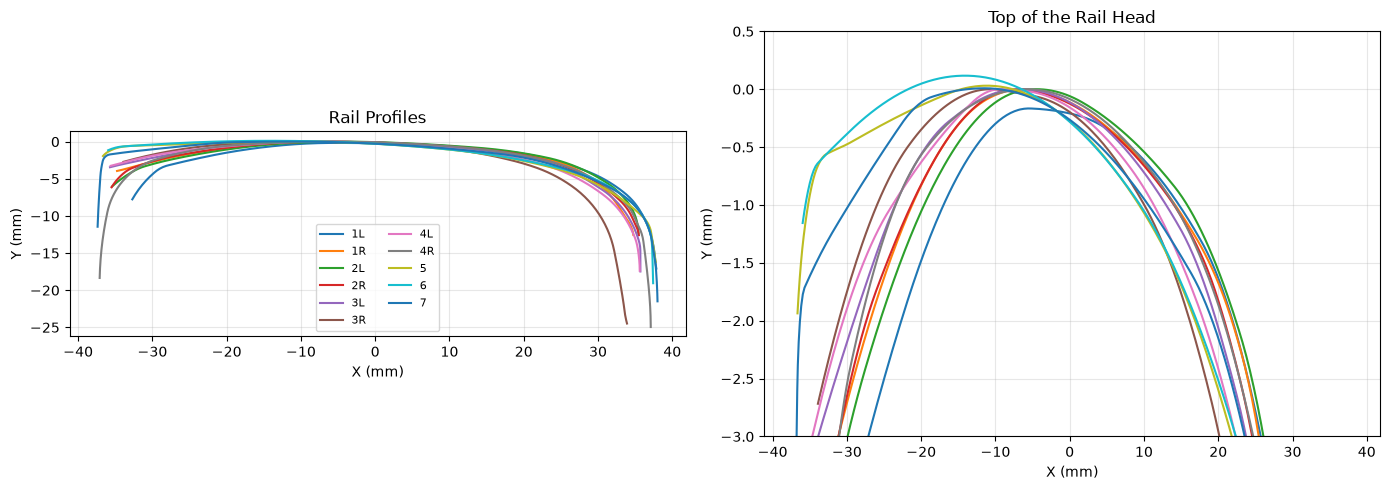

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, points in rails.items():
    axes[0].plot(points["X"], points["Y"], label=name)
    axes[1].plot(points["X"], points["Y"], label=name)

axes[0].set_title("Rail Profiles")
axes[0].set_aspect("equal")
axes[1].set_title("Top of the Rail Head")
axes[1].set_ylim(-3, 0.5)

for ax in axes:
    ax.set_xlabel("X (mm)")
    ax.set_ylabel("Y (mm)")
    ax.grid(alpha=0.3)

axes[0].legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

Profiles 5 and 6 look flatter and wider across the top than the others. Profile 7 is somewhere in between.

## Measure how rounded the top is

To put a number on this, I fit a parabola to the points within 20 mm of the highest point and turn it into a crown radius. A larger radius means a flatter rail head. I also measure how wide the head is within 1 mm of the top.

In [4]:
def crown_measurements(points, half_width=20):
    top = points.loc[points["Y"].idxmax()]
    near_top = points[(points["X"] - top["X"]).abs() < half_width]
    a = np.polyfit(near_top["X"], near_top["Y"], 2)[0]

    within_1mm = points[points["Y"] > top["Y"] - 1]
    return pd.Series({
        "crown_radius_mm": -1 / (2 * a),
        "width_within_1mm": within_1mm["X"].max() - within_1mm["X"].min(),
    })


shape = pd.DataFrame({name: crown_measurements(points) for name, points in rails.items()}).T
shape["Rail_Profile"] = shape.index.str[0].astype(int)
display(shape.round(1))

,crown_radius_mm,width_within_1mm,Rail_Profile
1L,122.2,34.3,1
1R,141.7,35.4,1
2L,144.1,35.1,2
2R,140.1,35.2,2
3L,159.7,36.2,3
3R,147.1,35.8,3
4L,153.0,34.8,4
4R,171.5,37.4,4
5,260.0,43.9,5
6,252.4,43.3,6


For profiles 1-4 I average the left and right rails so there is one value per rail profile. I also keep the left/right difference, since a mismatch between the two rails could matter too.

In [5]:
rail_shape = shape.groupby("Rail_Profile").agg(
    crown_radius_mm=("crown_radius_mm", "mean"),
    crown_radius_difference=("crown_radius_mm", lambda r: r.max() - r.min()),
    width_within_1mm=("width_within_1mm", "mean"),
)
display(rail_shape.round(1))

,crown_radius_mm,crown_radius_difference,width_within_1mm
Rail_Profile,,,
1,132.0,19.5,34.8
2,142.1,4.0,35.2
3,153.4,12.5,36.0
4,162.3,18.5,36.1
5,260.0,0.0,43.9
6,252.4,0.0,43.3
7,192.1,0.0,39.7


## Compare with the hunting results

I use the merged CSV and keep one row per car/truck/rail-profile assessment, since the truck results are repeated on both wheelsets. Then I summarize each rail profile.

In [6]:
data = pd.read_csv(data_folder / "final_merged_data.csv")

truck_results = (
    data.groupby(["Car", "Truck", "Rail_Profile"], as_index=False)
    .agg(
        hunted=("Empty_Truck_Hunted", "first"),
        critical_speed=("Min Empty Truck from Acc HS [mph]", "first"),
        eq_con=("Min Eq Con 3mm", "first"),
    )
)

by_rail = truck_results.groupby("Rail_Profile").agg(
    assessments=("hunted", "size"),
    hunting_rate=("hunted", "mean"),
    median_speed=("critical_speed", "median"),
    mean_eq_con=("eq_con", "mean"),
)

rail_summary = rail_shape.join(by_rail)
display(rail_summary.sort_values("crown_radius_mm").round(3))

print("Assessments at 80 mph:", (truck_results["critical_speed"] == 80).sum(), "of", len(truck_results))
print("Highest critical speed:", truck_results["critical_speed"].max())

,crown_radius_mm,crown_radius_difference,width_within_1mm,assessments,hunting_rate,median_speed,mean_eq_con
Rail_Profile,,,,,,,
1,131.963,19.538,34.823,28,0.786,60.805,0.280
2,142.077,3.994,35.151,28,0.786,61.585,0.262
3,153.412,12.536,36.013,28,0.571,67.250,0.237
4,162.255,18.464,36.097,28,0.750,64.290,0.221
7,192.073,0.000,39.742,28,0.607,66.480,0.219
6,252.391,0.000,43.305,28,0.536,70.560,0.128
5,260.028,0.000,43.926,28,0.464,80.000,0.112


Assessments at 80 mph: 70 of 196
Highest critical speed: 80.0


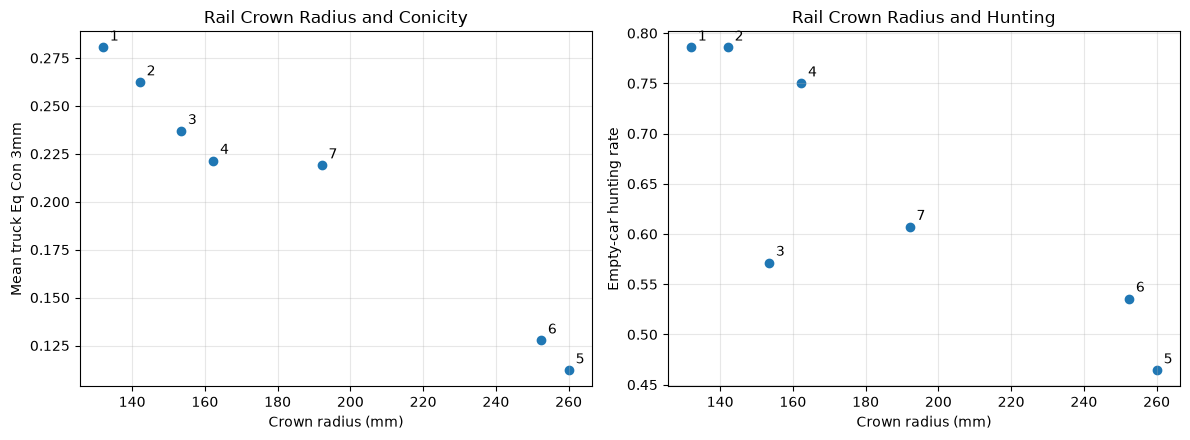

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, column, label in [
    (axes[0], "mean_eq_con", "Mean truck Eq Con 3mm"),
    (axes[1], "hunting_rate", "Empty-car hunting rate"),
]:
    ax.scatter(rail_summary["crown_radius_mm"], rail_summary[column])
    for rail, row in rail_summary.iterrows():
        ax.annotate(str(rail), (row["crown_radius_mm"], row[column]),
                    xytext=(5, 5), textcoords="offset points")
    ax.set_xlabel("Crown radius (mm)")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)

axes[0].set_title("Rail Crown Radius and Conicity")
axes[1].set_title("Rail Crown Radius and Hunting")
plt.tight_layout()
plt.show()

In [8]:
# Rank correlations across the 7 rail profiles
display(
    rail_summary[["crown_radius_mm", "crown_radius_difference", "width_within_1mm",
                  "mean_eq_con", "hunting_rate", "median_speed"]]
    .corr(method="spearman")
    .loc[["crown_radius_mm", "crown_radius_difference", "width_within_1mm"],
         ["mean_eq_con", "hunting_rate", "median_speed"]]
    .round(2)
)

,mean_eq_con,hunting_rate,median_speed
crown_radius_mm,-1.00,-0.88,0.89
crown_radius_difference,0.82,0.69,-0.74
width_within_1mm,-1.00,-0.88,0.89


## Critical speed on each rail profile

The hunting rate only says whether a truck hunted. Here I look at the critical speeds themselves. 80 mph is the highest value in the data, so a lot of the boxes run into that ceiling.

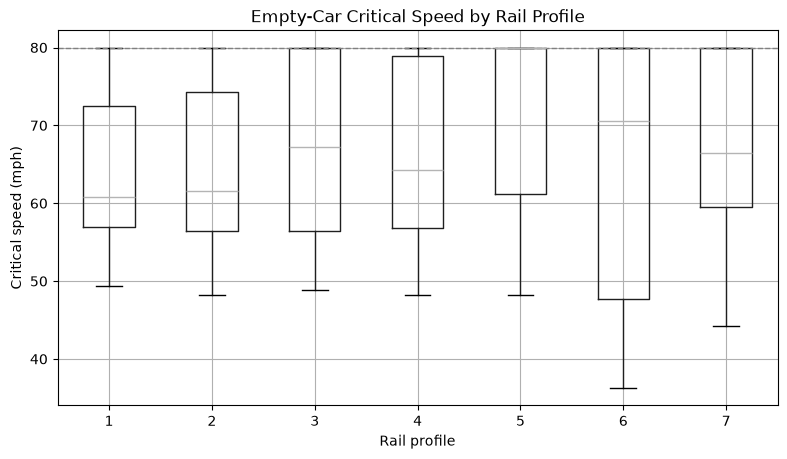

,count,mean,std,min,25%,50%,75%,max
Rail_Profile,,,,,,,,
1,28.0,64.3,10.2,49.4,56.9,60.8,72.5,80.0
2,28.0,64.6,10.8,48.2,56.4,61.6,74.3,80.0
3,28.0,67.6,12.0,48.9,56.5,67.2,80.0,80.0
4,28.0,65.2,11.2,48.2,56.8,64.3,78.9,80.0
5,28.0,71.1,11.6,48.2,61.2,80.0,80.0,80.0
6,28.0,65.2,15.9,36.2,47.8,70.6,80.0,80.0
7,28.0,68.4,11.1,44.3,59.5,66.5,80.0,80.0


In [9]:
truck_results.boxplot(column="critical_speed", by="Rail_Profile", figsize=(9, 5))
plt.axhline(80, color="gray", linestyle="--", linewidth=1)
plt.xlabel("Rail profile")
plt.ylabel("Critical speed (mph)")
plt.title("Empty-Car Critical Speed by Rail Profile")
plt.suptitle("")
plt.show()

display(truck_results.groupby("Rail_Profile")["critical_speed"].describe().round(1))

Profile 5 has the highest median, but profile 6 has the lowest single critical speed and the widest spread. A flatter rail does not help every truck.

## Rail profile or truck?

Each of the 28 trucks was run on all seven rail profiles, so I can check how much of the spread in critical speed comes from the rail profile and how much comes from the truck. For each one I take the group averages and see how much of the total variation they account for.

In [10]:
truck_results["truck_id"] = truck_results["Car"].astype(str) + "-" + truck_results["Truck"].astype(str)

overall_mean = truck_results["critical_speed"].mean()
total_variation = ((truck_results["critical_speed"] - overall_mean) ** 2).sum()

for group in ["Rail_Profile", "truck_id"]:
    group_means = truck_results.groupby(group)["critical_speed"].transform("mean")
    share = ((group_means - overall_mean) ** 2).sum() / total_variation
    print(f"{group}: {share:.0%} of the variation in critical speed")

Rail_Profile: 4% of the variation in critical speed
truck_id: 53% of the variation in critical speed


The truck matters much more than the rail profile. Rail profile changes how often hunting happens overall, but most of the difference in critical speed comes from the trucks, which is where the wheel profiles come in.

## How often each truck hunts

The project description asks which profiles hunt frequently, occasionally, or not at all. I count how many of the seven rail profiles each truck hunted on.

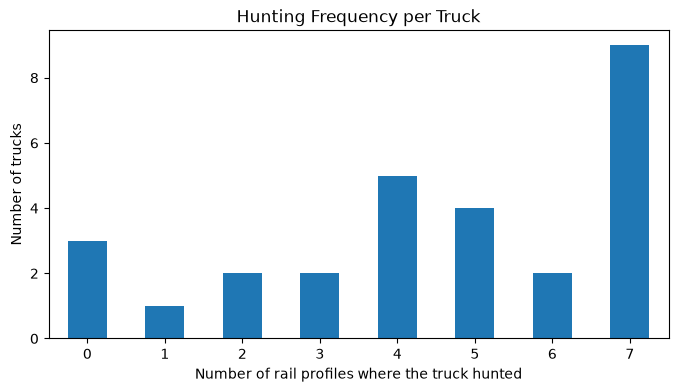

,Rail_Profile,1,2,3,4,5,6,7,rails_hunted
Car,Truck,,,,,,,,
2,1,0,0,0,0,0,0,0,0
3,2,0,0,0,0,0,0,0,0
5,2,0,0,0,0,0,0,0,0
12,2,0,0,0,0,0,0,1,1
5,1,1,1,0,0,0,0,0,2
2,2,1,0,0,0,0,0,1,2
4,1,1,1,0,0,0,0,1,3
1,2,1,1,0,1,0,0,0,3
13,1,0,1,0,1,1,1,0,4


In [11]:
hunting_table = truck_results.pivot_table(
    index=["Car", "Truck"], columns="Rail_Profile", values="hunted", aggfunc="first"
).astype(int)
hunting_table["rails_hunted"] = hunting_table.sum(axis=1)

hunting_table["rails_hunted"].value_counts().sort_index().plot(kind="bar", figsize=(8, 4))
plt.xlabel("Number of rail profiles where the truck hunted")
plt.ylabel("Number of trucks")
plt.title("Hunting Frequency per Truck")
plt.xticks(rotation=0)
plt.show()

display(hunting_table.sort_values("rails_hunted"))

Most trucks are near one end or the other. Nine trucks hunt on all seven rail profiles and three never hunt. That gives us natural groups for the clustering part of the project: trucks that always hunt, trucks that sometimes hunt, and trucks that never hunt.

## Conicity within each rail profile

Across rail profiles, conicity lines up well with the rail shape. Here I check whether conicity also explains the critical speed for trucks on the same rail profile.

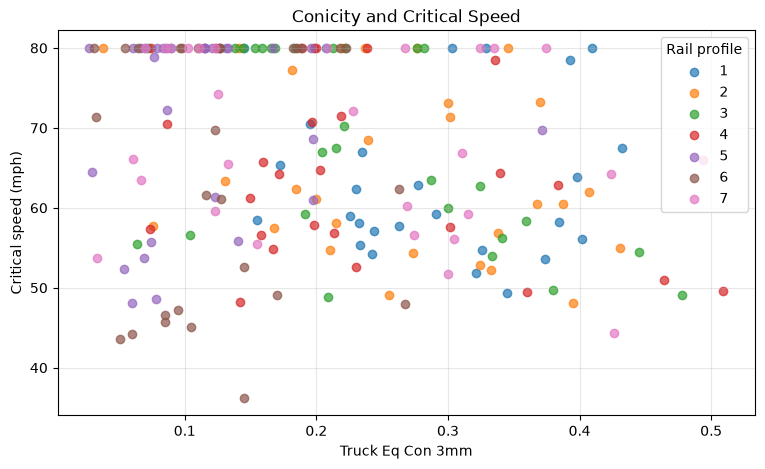

,spearman_eq_con_vs_speed
Rail_Profile,
1,-0.18
2,-0.28
3,-0.51
4,-0.27
5,0.16
6,0.15
7,-0.18


In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
for rail, group in truck_results.groupby("Rail_Profile"):
    ax.scatter(group["eq_con"], group["critical_speed"], label=str(rail), alpha=0.7)

ax.set_xlabel("Truck Eq Con 3mm")
ax.set_ylabel("Critical speed (mph)")
ax.set_title("Conicity and Critical Speed")
ax.legend(title="Rail profile")
ax.grid(alpha=0.3)
plt.show()

within_rail = truck_results.groupby("Rail_Profile")[["eq_con", "critical_speed"]].apply(
    lambda group: group["eq_con"].corr(group["critical_speed"], method="spearman")
)
display(within_rail.round(2).to_frame(name="spearman_eq_con_vs_speed"))

In [13]:
for cutoff in [0.15, 0.20, 0.25]:
    low = truck_results[truck_results["eq_con"] < cutoff]
    high = truck_results[truck_results["eq_con"] >= cutoff]
    print(f"Eq Con < {cutoff}: {low['hunted'].mean():.0%} hunted ({len(low)} assessments) | "
          f">= {cutoff}: {high['hunted'].mean():.0%} hunted ({len(high)} assessments)")

Eq Con < 0.15: 49% hunted (73 assessments) | >= 0.15: 73% hunted (123 assessments)
Eq Con < 0.2: 52% hunted (104 assessments) | >= 0.2: 78% hunted (92 assessments)
Eq Con < 0.25: 55% hunted (132 assessments) | >= 0.25: 83% hunted (64 assessments)


## What I found

The seven rail profiles have clearly different head shapes. Profiles 5 and 6 have the flattest tops (crown radius around 250-260 mm) and profile 1 has the roundest (around 130 mm).

When I sort the rail profiles by crown radius, the average equivalent conicity goes down in the same order. Hunting mostly follows: the two flattest rails (5 and 6) have the lowest hunting rates and the highest median critical speeds. Profile 4 does not fit as well. It hunts almost as much as profiles 1 and 2 even though its crown is in the middle. Profiles 1 and 4 have the biggest differences between their left and right rails (about 19 mm in crown radius), so a mismatch between the two rails may be worth looking at.

Out of 196 truck/rail assessments, 70 are exactly 80 mph and none are higher. It looks like 80 mph is the top speed tested, so a truck at 80 mph means no hunting was found up to that speed.

This is only seven rail profiles, so the correlations are a starting point and not strong evidence.

Even though the rail profile changes the hunting rate, it only accounts for about 4% of the variation in critical speed. The truck accounts for about 53%. So the trucks, and the wheel profiles on them, matter much more than which rail they run on. A flatter rail also does not help every truck: profile 6 has the lowest critical speed in the data.

Hunting frequency per truck is split toward the ends. Nine trucks hunt on all seven rail profiles and three never hunt, with the rest in between. Comparing the wheel profiles of the always-hunt and never-hunt trucks seems like a good next step.

Conicity is lower on the flatter rails, and assessments with Eq Con below 0.20 hunted less often than the rest. Within a single rail profile, though, conicity is only weakly related to critical speed, and on profiles 5 and 6 the relationship goes the other way. Conicity alone does not explain which trucks hunt, which supports looking for other wheel shape descriptors.

**Next:** Compare the wheel measurements for the trucks that always hunt with the trucks that never hunt. Confirm with MxV which side of each rail profile is the gauge side and whether profiles 5-7 use the same shape for both rails. Then use the `.wnt` files to see how each wheel and rail fit together.